In [1]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

import mpl_toolkits as mpl

from pathlib import Path

import seaborn as sns

import api

import random

%matplotlib inline

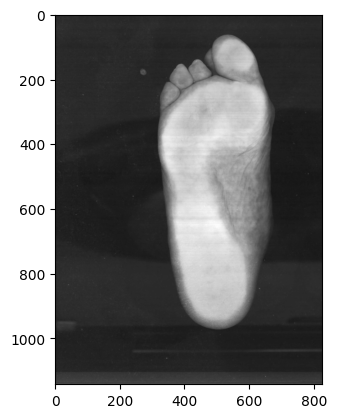

In [23]:
annotations_path = '../annotations.xml'

image = None
mask = None

for i, annot in enumerate(api.iter_annotated_images(annotations_path)):
    if i == 10:
        
        imgAndMask = api.get_image_and_mask(
            annotations_path,
            image_id=annot.image_id,
            imread_flags=cv.IMREAD_COLOR_RGB
        )
        image = cv.cvtColor(imgAndMask.image, cv.COLOR_RGB2GRAY)
        mask = imgAndMask.mask 
        plt.imshow(cv.cvtColor(imgAndMask.image, cv.COLOR_RGB2GRAY), 'gray')

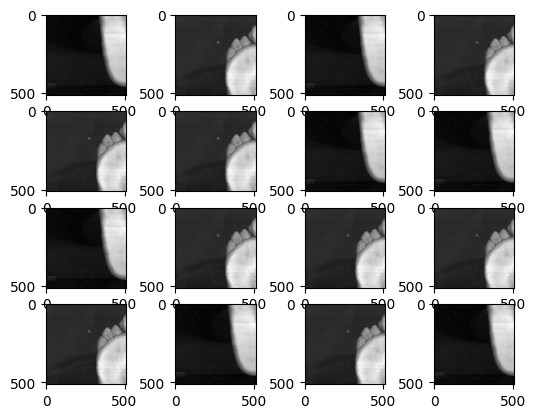

In [12]:
window_size = 512
windowH = image.shape[0] // window_size
windowW = image.shape[1] // window_size


patches = []

for row in range(windowH):
    for col in range(windowW):
        # left top corner position of sliding window
        x = col * window_size
        y = row * window_size

        # for yy in range(window_size):
        #     for xx in range(window_size):
        #         absoluteX = x + xx
        #         absoluteY = y + yy

        patch = image[y:y + window_size, x:x + window_size]
        # print(np.mean(patch))
        patches.append(patch)

fig, axs = plt.subplots(4, 4)
axs = axs.flatten()

for i, patch in enumerate(random.choices(patches, k=16)):
    axs[i].imshow(patch, 'gray')
        

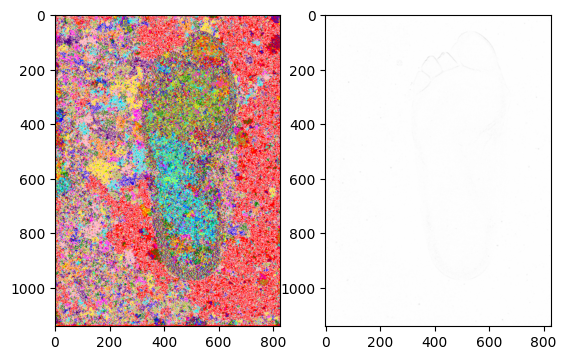

In [54]:
image2 = np.astype(image.copy(), np.uint8)

laplacian = cv.convertScaleAbs(cv.Laplacian(image2, cv.CV_16S, ksize=9))
sobel = cv.convertScaleAbs(cv.Sobel(image2, cv.CV_16S, 1, 1))
# sobel = cv.convertScaleAbs(cv.rob(image2, cv.CV_16S, 1, 1))

contours, hierarchy = cv.findContours(image2, cv.RETR_TREE, cv.CHAIN_APPROX_NONE)

# print(contours.shape)
# contourImage = image2.copy()
# cv.drawContours(contourImage, contours, -1, (255,255, 255), 3)
fig, axs = plt.subplots(1, 2)
axs[0].imshow(ski.color.label2rgb(ski.measure.label(~sobel,connectivity=2)), 'gray')
axs[1].imshow(cv.normalize(~sobel, None, 0, 255, cv.NORM_MINMAX), 'gray')